# 04 Deforestation and forest resources

**Questions**
1. Which African countries are losing the most forest, in absolute and relative terms?
2. Is agricultural expansion associated with forest loss?
3. How does forest cover relate to economic development?

**What I expect going in**
- **H1** Tree cover loss is concentrated in the humid tropical belt (Central and West Africa) and Madagascar.
- **H2** Countries that expanded agricultural land more also lost more forest.

**Read before interpreting:** FAO forest area is interpolated between assessment years for many countries (notebook 01 flags it), so it is used for levels and long changes only, not annual moves. Satellite tree cover loss includes plantation harvest, shifting cultivation and fire, so it is not the same as deforestation. Its method changed around 2011 and 2015, so trends use 3-year averages.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "04 forests"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

## 1. Forest cover today and since 2000

In [2]:
fa = change("C01")
print(f"Forest share of land fell in {(fa['abs_change'] < 0).sum()} of {len(fa)} countries since 2000 to 2002; "
      f"median change {fa['abs_change'].median():+.2f} points")
flags = pd.read_csv(DATA / "quality flags.csv")
interp = flags[(flags["indicator_id"] == "C01") & (flags["flag"] == "suspected interpolation") & flags["iso3"].isin(AFRICA)]["iso3"].nunique()
print(f"Caution: {interp} countries' FAO forest series show suspected interpolation")
fa.sort_values("abs_change").head(12)

Forest share of land fell in 41 of 52 countries since 2000 to 2002; median change -2.38 points
Caution: 44 countries' FAO forest series show suspected interpolation


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
BEN,Benin,2024,28.119,49.071,-20.953,-42.698
LBR,Liberia,2024,66.104,82.744,-16.640,-20.110
GMB,Gambia,2024,21.344,34.791,-13.447,-38.651
TZA,Tanzania,2024,49.626,60.659,-11.034,-18.190
BFA,Burkina Faso,2024,12.269,22.820,-10.551,-46.236
SYC,Seychelles,2024,58.512,69.007,-10.495,-15.209
MWI,Malawi,2024,21.995,32.241,-10.246,-31.779
AGO,Angola,2024,51.153,60.562,-9.409,-15.537
MOZ,Mozambique,2024,41.341,49.151,-7.810,-15.890


**Forest share of land fell in 41 of 52 countries since 2000 to 2002, with the largest falls in West Africa.**

- Benin lost 21.0 points of land area to forest loss, Liberia 16.6, Gambia 13.4 and Tanzania 11.0.
- 44 countries' FAO series show suspected interpolation, so these are long-run changes, not annual measurements.

## 2. Tree cover loss: absolute and relative (H1)

,country,value,year,au_region
iso3,,,,
COD,DR Congo,"1,330.163",2023 to 2025,Central
AGO,Angola,309.777,2023 to 2025,Southern
MOZ,Mozambique,269.778,2023 to 2025,Southern
MDG,Madagascar,265.758,2023 to 2025,East
ZMB,Zambia,232.316,2023 to 2025,Southern
TZA,Tanzania,219.512,2023 to 2025,East
CMR,Cameroon,196.538,2023 to 2025,Central
CIV,Côte d'Ivoire,189.497,2023 to 2025,West
LBR,Liberia,155.881,2023 to 2025,West


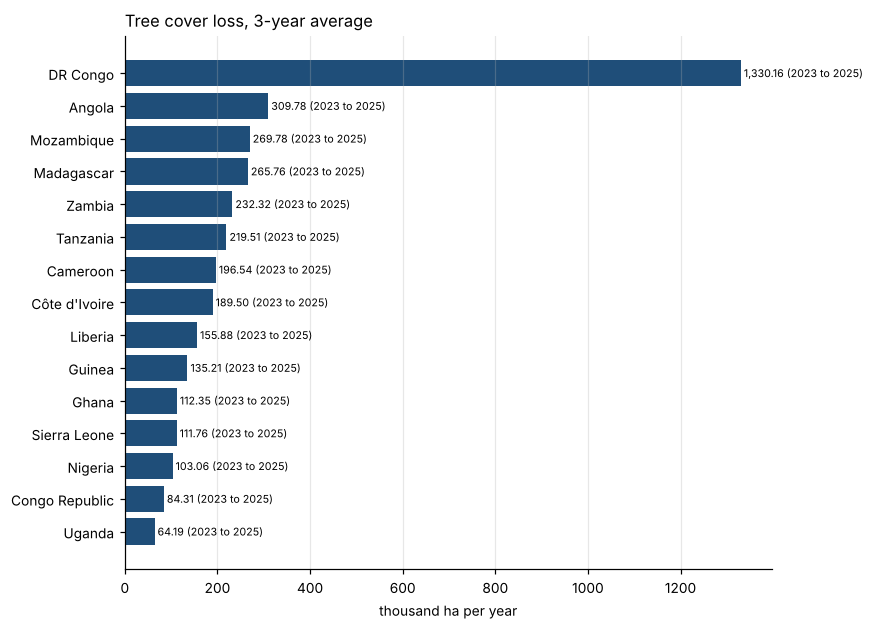

Share of Africa's recent tree cover loss by AU region (%):


au_region
Central    42.625
Southern   21.621
West       20.456
East       14.918
North       0.379
Name: value, dtype: float64

,country,value
iso3,,
CIV,Côte d'Ivoire,4.921
SLE,Sierra Leone,4.551
GIN,Guinea,2.742
UGA,Uganda,2.678
MDG,Madagascar,2.644
LBR,Liberia,2.448
GHA,Ghana,1.600
CMR,Cameroon,1.020
COD,DR Congo,0.954


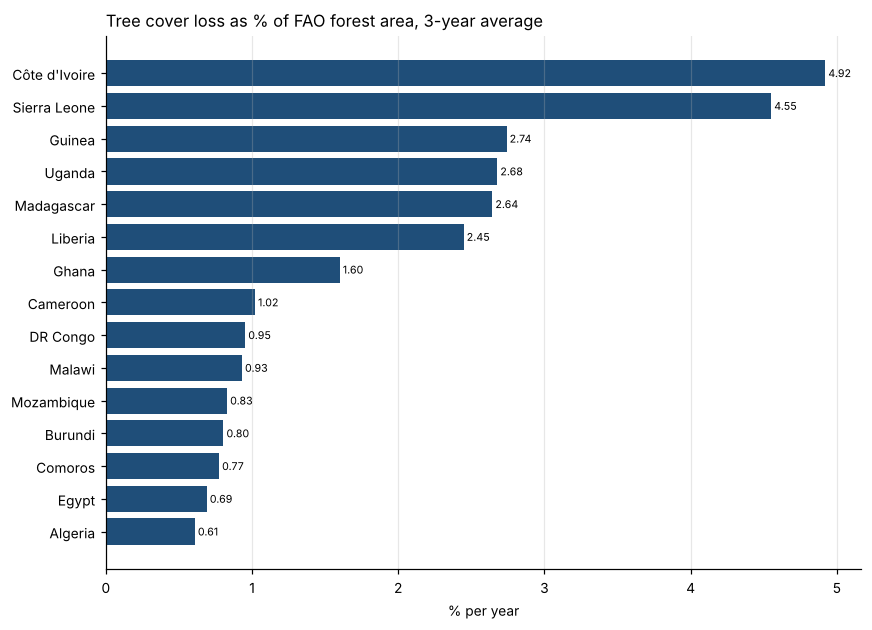

In [3]:
if has("C03"):
    tcl = af[af["indicator_id"] == "C03"]
    recent = tcl[tcl["year"] >= tcl["year"].max() - 2].groupby("iso3")["value"].mean()
    t = pd.DataFrame({"country": recent.index.map(name), "value": recent / 1000, "year": f"{tcl['year'].max() - 2} to {tcl['year'].max()}"})
    t = t.sort_values("value", ascending=False)
    t["au_region"] = t.index.map(cty["au_region"])
    display(t.head(10))
    barh(t, "value", "Tree cover loss, 3-year average", "thousand ha per year", "tree cover loss ranking.png")
    print("Share of Africa's recent tree cover loss by AU region (%):")
    display((t.groupby("au_region")["value"].sum() / t["value"].sum() * 100).sort_values(ascending=False))
if "X02" in panel:
    x = afp[afp["year"] >= afp.loc[afp["X02"].notna(), "year"].max() - 2].groupby("iso3")["X02"].mean().dropna()
    rel = pd.DataFrame({"country": x.index.map(name), "value": x}).sort_values("value", ascending=False)
    display(rel.head(10))
    barh(rel, "value", "Tree cover loss as % of FAO forest area, 3-year average", "% per year", "relative loss ranking.png")

**DR Congo alone accounts for a third of Africa's recent tree cover loss (33.0%). Relative to forest area, West Africa is losing fastest.**

- In absolute terms (3-year average to 2025), DR Congo leads with 1.33 million ha a year, followed by Angola, Mozambique, Madagascar, Zambia (232,000 ha) and Tanzania.
- Central Africa accounts for 42.6% of the continent's recent loss, Southern 21.6%, West 20.5%, East 14.9% and North 0.4%. H1 is supported for Central Africa, but Southern Africa is close behind West Africa.
- Relative to FAO forest area, Côte d'Ivoire (4.9% a year), Sierra Leone (4.6%), Guinea (2.7%), Uganda, Madagascar and Liberia are highest.

## 3. Trend in tree cover loss (3-year moving average)

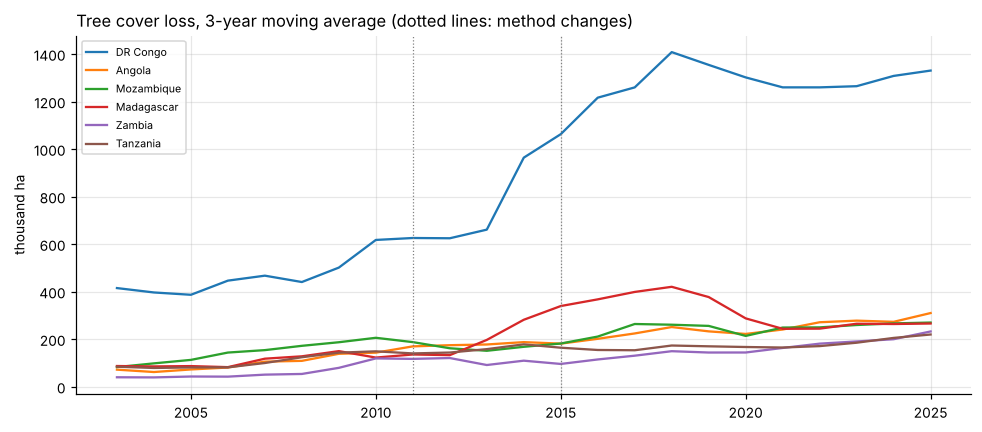

In [4]:
if "C03" in panel:
    top = t.index[:6]
    fig, ax = plt.subplots(figsize=(9, 4))
    for iso in top:
        s = afp[afp["iso3"] == iso].set_index("year")["C03"].dropna().sort_index().rolling(3).mean() / 1000
        ax.plot(s.index, s.values, label=name.get(iso, iso))
    for yr in (2011, 2015):
        ax.axvline(yr, color=GREY, lw=0.8, ls=":")
    ax.set_title("Tree cover loss, 3-year moving average (dotted lines: method changes)", loc="left"); ax.set_ylabel("thousand ha")
    ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(OUT / "tree cover loss trend.png", dpi=150); plt.show()

**Africa's recorded tree cover loss roughly tripled, from about 1.3 million ha a year in 2001 to 2003 to about 4 million ha in 2022 to 2024.**

The annual total peaked at 5.1 million ha in 2017. Part of the rise reflects satellite method changes in 2011 and 2015, so the size of the increase is uncertain, but the direction holds in the 3-year averages.

## 4. Primary forest loss

In [5]:
if "C04" in panel:
    pf = af[af["indicator_id"] == "C04"]
    tot = pf.groupby("iso3")["value"].sum().sort_values(ascending=False) / 1000
    print(f"{(tot > 0).sum()} countries record any primary forest loss (humid tropical primary forest only; missing elsewhere is not zero)")
    display(pd.DataFrame({"country": tot.index.map(name), "cumulative_kha": tot}).head(12))

30 countries record any primary forest loss (humid tropical primary forest only; missing elsewhere is not zero)


,country,cumulative_kha
iso3,,
COD,DR Congo,"8,005.873"
MDG,Madagascar,"1,222.633"
CMR,Cameroon,"1,177.200"
COG,Congo Republic,522.378
LBR,Liberia,422.687
CIV,Côte d'Ivoire,384.667
GAB,Gabon,310.535
CAF,Central African Republic,250.640
AGO,Angola,222.248


**Primary forest loss is concentrated in the Congo Basin and Madagascar.**

- DR Congo lost 8.0 million ha of humid primary forest since 2002, against 1.2 million ha each in Madagascar and Cameroon.
- Only 30 countries record any, because the series covers humid tropical forest only.

## 5. Agricultural expansion and forest loss (H2, period level)

H2: change in agricultural land vs change in forest share, Spearman rho = -0.53 (p = 0.000), n = 52


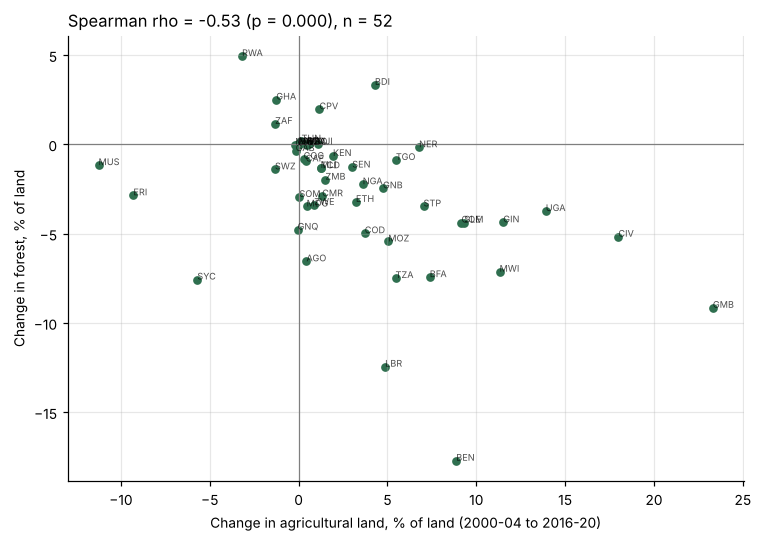

In [6]:
if has("C07", "C01"):
    def period_change(i, a=(2000, 2004), b=(2016, 2020)):
        s = afp.groupby("iso3").apply(lambda g: g.loc[g["year"].between(*b), i].mean() - g.loc[g["year"].between(*a), i].mean())
        return s
    d = pd.DataFrame({"agri_change": period_change("C07"), "forest_change": period_change("C01")}).dropna()
    rho, p = stats.spearmanr(d["agri_change"], d["forest_change"])
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(d["agri_change"], d["forest_change"], color=GREEN, s=22)
    for iso, r in d.iterrows():
        ax.annotate(iso, (r["agri_change"], r["forest_change"]), fontsize=6, alpha=0.7)
    ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
    ax.set_xlabel("Change in agricultural land, % of land (2000-04 to 2016-20)"); ax.set_ylabel("Change in forest, % of land")
    print(f"H2: change in agricultural land vs change in forest share, Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(d)}")
    ax.set_title(f"Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(d)}", loc="left")
    fig.tight_layout(); fig.savefig(OUT / "agriculture vs forest.png", dpi=150); plt.show()

**H2 supported at period level: countries that expanded agricultural land more lost more forest share (Spearman rho = -0.53, p < 0.001, n = 52).**

The within-country panel test in 08 points the same way.

## 6. Forest cover and income

In [7]:
if has("G02", "C01"):
    s = afp[afp["year"] >= 2015].groupby("iso3")[["G02", "C01"]].mean().dropna()
    rho, p = stats.spearmanr(s["G02"], s["C01"])
    print(f"Forest share vs GDP per capita (2015 onward averages): Spearman rho = {rho:.2f}, p = {p:.3f}, n = {len(s)}")

Forest share vs GDP per capita (2015 onward averages): Spearman rho = -0.05, p = 0.741, n = 52


**Forest cover is unrelated to income across African countries (rho = -0.05, p = 0.74).**

## 7. Save tables

In [8]:
save_excel("forest results.xlsx", {"Forest share change": fa, **({"Tree cover loss": t} if "t" in globals() else {}),
                                   **({"Relative loss": rel} if "rel" in globals() else {}), **({"Agri vs forest": d} if "d" in globals() else {})})

['agriculture vs forest.png',
 'forest results.xlsx',
 'relative loss ranking.png',
 'tree cover loss ranking.png',
 'tree cover loss trend.png']

## What I found

- **Forest is shrinking almost everywhere:** forest share fell in 41 of 52 countries, by a median 2.4 points since 2000 to 2002.
- **Tree cover loss has roughly tripled since the early 2000s,** to about 4 million ha a year, even allowing for method changes.
- **DR Congo dominates the absolute loss** (1.33 million ha a year, and 8.0 million ha of primary forest since 2002). Zambia is fifth in Africa at 232,000 ha a year.
- **West Africa is losing fastest relative to what it has:** Côte d'Ivoire and Sierra Leone lose about 5% of their forest area a year.
- **Agricultural expansion goes with forest loss (H2 supported,** rho = -0.53 across countries, and positive and significant within countries in 08).

**Why it matters for finance:** deforestation is now a lending and supply-chain risk, not just an environmental metric. The EU Deforestation Regulation (EUDR) puts it at the centre of export financing for cocoa, coffee, timber and soy. Banks and agribusiness financiers in Côte d'Ivoire, Ghana, Cameroon and DR Congo need country-level forest-loss data in credit and ESG due diligence.